# Experiment 10: Design of a Fuzzy Logic Controller

**Aim:** To design a simple Fuzzy Logic Controller using Python and scikit-fuzzy by combining membership functions, fuzzy rules, fuzzy inference, and defuzzification.

## Theory
A **Fuzzy Logic Controller (FLC)** has four blocks:
1. **Fuzzifier**: crisp inputs → fuzzy sets
2. **Rule base / Knowledge base**: IF-THEN rules
3. **Inference engine** (Mamdani)
4. **Defuzzifier**: fuzzy output → crisp control action

Problem: *Air-conditioner / fan controller* with inputs **Temperature** and **Humidity**, output **Fan Speed**.

### Step 1: Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from mpl_toolkits.mplot3d import Axes3D
%matplotlib inline

### Step 2: Fuzzifier - define variables and membership functions

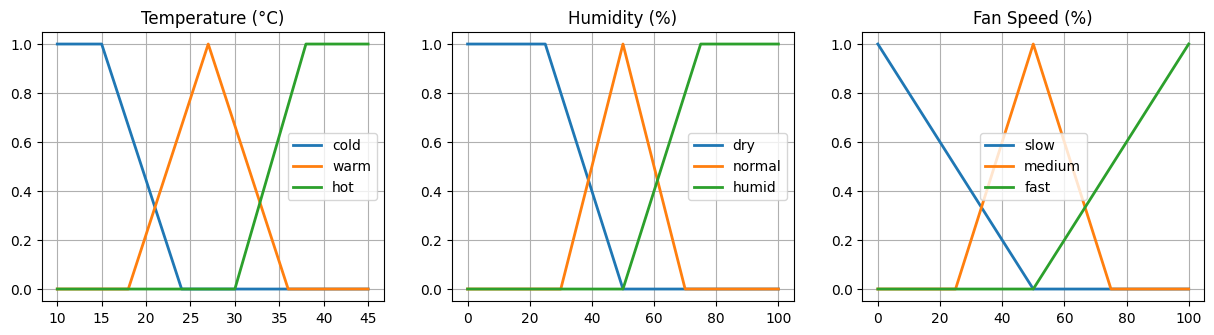

In [2]:
temperature = ctrl.Antecedent(np.arange(10, 46, 1), 'temperature')   # °C
humidity    = ctrl.Antecedent(np.arange(0, 101, 1),  'humidity')      # %
fan_speed   = ctrl.Consequent(np.arange(0, 101, 1),  'fan_speed')     # %

temperature['cold'] = fuzz.trapmf(temperature.universe, [10, 10, 15, 24])
temperature['warm'] = fuzz.trimf(temperature.universe,  [18, 27, 36])
temperature['hot']  = fuzz.trapmf(temperature.universe, [30, 38, 45, 45])

humidity['dry']    = fuzz.trapmf(humidity.universe, [0, 0, 25, 50])
humidity['normal'] = fuzz.trimf(humidity.universe,  [30, 50, 70])
humidity['humid']  = fuzz.trapmf(humidity.universe, [50, 75, 100, 100])

fan_speed['slow']   = fuzz.trimf(fan_speed.universe, [0, 0, 50])
fan_speed['medium'] = fuzz.trimf(fan_speed.universe, [25, 50, 75])
fan_speed['fast']   = fuzz.trimf(fan_speed.universe, [50, 100, 100])

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for var, a, name in zip([temperature, humidity, fan_speed], ax, ['Temperature (°C)', 'Humidity (%)', 'Fan Speed (%)']):
    for term in var.terms: a.plot(var.universe, var[term].mf, lw=2, label=term)
    a.set_title(name); a.legend(); a.grid(True)
plt.show()

### Step 3: Rule base (3 x 3 = 9 rules)

In [3]:
rules = [
    ctrl.Rule(temperature['cold'] & humidity['dry'],    fan_speed['slow']),
    ctrl.Rule(temperature['cold'] & humidity['normal'], fan_speed['slow']),
    ctrl.Rule(temperature['cold'] & humidity['humid'],  fan_speed['slow']),
    ctrl.Rule(temperature['warm'] & humidity['dry'],    fan_speed['slow']),
    ctrl.Rule(temperature['warm'] & humidity['normal'], fan_speed['medium']),
    ctrl.Rule(temperature['warm'] & humidity['humid'],  fan_speed['medium']),
    ctrl.Rule(temperature['hot']  & humidity['dry'],    fan_speed['medium']),
    ctrl.Rule(temperature['hot']  & humidity['normal'], fan_speed['fast']),
    ctrl.Rule(temperature['hot']  & humidity['humid'],  fan_speed['fast']),
]
print(f"{len(rules)} rules created")

9 rules created


### Step 4: Inference engine + defuzzifier (centroid)

Temperature = 34 °C, Humidity = 70 %  ->  Fan speed = 70.96 %


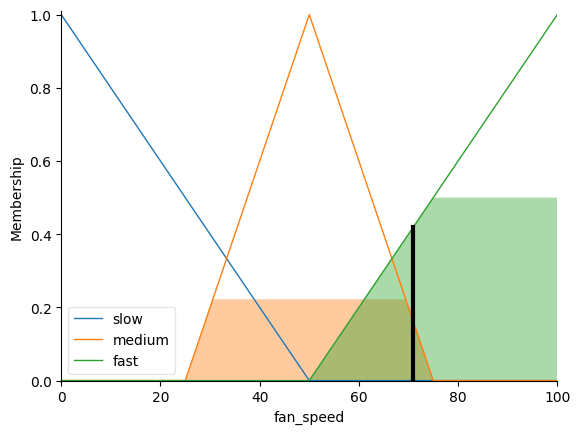

In [4]:
fan_speed.defuzzify_method = 'centroid'
controller = ctrl.ControlSystem(rules)
flc = ctrl.ControlSystemSimulation(controller)

flc.input['temperature'] = 34
flc.input['humidity']    = 70
flc.compute()
print(f"Temperature = 34 °C, Humidity = 70 %  ->  Fan speed = {flc.output['fan_speed']:.2f} %")
fan_speed.view(sim=flc); plt.show()

### Step 5: Test the controller on different conditions

In [5]:
import pandas as pd
tests = [(12, 20), (20, 50), (27, 50), (27, 85), (35, 30), (40, 80), (44, 95)]
rows = []
for t, h in tests:
    sim = ctrl.ControlSystemSimulation(controller)
    sim.input['temperature'] = t; sim.input['humidity'] = h
    sim.compute()
    rows.append({'Temperature (°C)': t, 'Humidity (%)': h, 'Fan Speed (%)': round(sim.output['fan_speed'], 2)})
pd.DataFrame(rows)

,Temperature (°C),Humidity (%),Fan Speed (%)
0,12,20,16.67
1,20,50,30.03
2,27,50,50.00
3,27,85,50.00
4,35,30,45.58
5,40,80,83.33
6,44,95,83.33


### Step 6: Control surface of the FLC

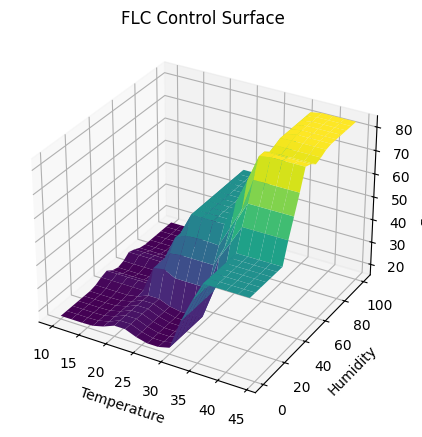

In [6]:
tx = np.arange(10, 46, 2); hx = np.arange(0, 101, 5)
T, H = np.meshgrid(tx, hx); F = np.zeros_like(T, dtype=float)
sim = ctrl.ControlSystemSimulation(controller)
for i in range(T.shape[0]):
    for j in range(T.shape[1]):
        sim.input['temperature'] = T[i, j]; sim.input['humidity'] = H[i, j]
        sim.compute(); F[i, j] = sim.output['fan_speed']

fig = plt.figure(figsize=(8, 5)); ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T, H, F, cmap='viridis', edgecolor='none')
ax.set_xlabel('Temperature'); ax.set_ylabel('Humidity'); ax.set_zlabel('Fan Speed')
ax.set_title('FLC Control Surface'); plt.show()

### Step 7: Simulate the controller over time (temperature rising)

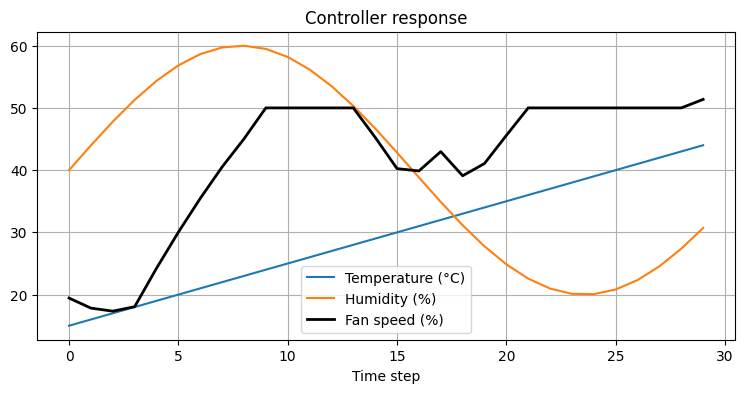

In [7]:
time = np.arange(0, 30)
temp_profile = 15 + time * 1.0              # temperature rises from 15 to 44 °C
hum_profile  = 40 + 20*np.sin(time/5)       # humidity fluctuates
speed = []
sim = ctrl.ControlSystemSimulation(controller)
for t, h in zip(temp_profile, hum_profile):
    sim.input['temperature'] = t; sim.input['humidity'] = h
    sim.compute(); speed.append(sim.output['fan_speed'])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(time, temp_profile, label='Temperature (°C)')
ax.plot(time, hum_profile,  label='Humidity (%)')
ax.plot(time, speed, 'k', lw=2, label='Fan speed (%)')
ax.set_xlabel('Time step'); ax.legend(); ax.grid(True); ax.set_title('Controller response'); plt.show()

## Conclusion
A complete Fuzzy Logic Controller was designed by combining membership functions (fuzzification), a 9-rule base, Mamdani inference and centroid defuzzification. The control surface shows a smooth non-linear mapping from temperature and humidity to fan speed.